<a href="https://colab.research.google.com/github/uppunurigeethika-ai/job-market-skill-analysis-system/blob/main/Job_Market_Data_Analysis(final).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

DATASET_PATH = "/content/job_market_skill_analysis_synthetic_2500.csv"

data = pd.read_csv(DATASET_PATH)

print("Dataset loaded successfully!")
print("Total records:", len(data))
print("Total columns:", len(data.columns))

display(data.head())

Dataset loaded successfully!
Total records: 2500
Total columns: 14


,Job_ID,Job_Title,Company,Location,Posted_Date,Experience,Salary_Min_LPA,Salary_Max_LPA,Salary_Midpoint_LPA,Skills,Education,Employment_Type,Work_Mode,Fresher_Friendly
0,JOB00001,Data Scientist,Aster Technologies,Bengaluru,2024-02-02,Fresher,4.39,7.10,5.74,"TensorFlow, Statistics, Python",B.Sc,Full-time,Remote,Yes
1,JOB00002,Web Developer,BrightPath IT,Bengaluru,2024-08-08,3-5 years,13.60,16.34,14.97,"Node.js, JavaScript, HTML, React, CSS, Git",B.Tech,Full-time,Hybrid,No
2,JOB00003,Business Analyst,BrightPath IT,Remote,2025-09-25,Fresher,2.53,5.60,4.06,"Communication, Excel, Power BI",B.Sc,Full-time,On-site,No
3,JOB00004,Cloud Engineer,BluePeak Systems,Remote,2024-09-30,6-8 years,33.77,40.14,36.95,"Docker, Kubernetes, Python, AWS, Linux, Networ...",B.Sc,Full-time,On-site,Yes
4,JOB00005,SAP ABAP Developer,BrightPath IT,Noida,2026-04-04,Fresher,6.32,11.24,8.78,"Debugging, OOP, SAP ABAP, SQL",M.Tech,Full-time,Remote,No


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


Dataset loaded successfully!
Total records: 2500

===== JOB MARKET SKILL ANALYSIS SYSTEM =====
1. Dataset Overview
2. Preprocessing Report
3. Top Skills
4. Job Role Analysis
5. Location Analysis
6. Salary by Experience
7. Fresher-Friendly Jobs
8. Skills for a Selected Role
9. View Graphs
0. Exit

--- GRAPH MENU ---
1. Top Skills
2. Job Role Distribution
3. Top Locations
4. Salary by Experience
5. Fresher-Friendly Jobs
0. Return to Main Menu


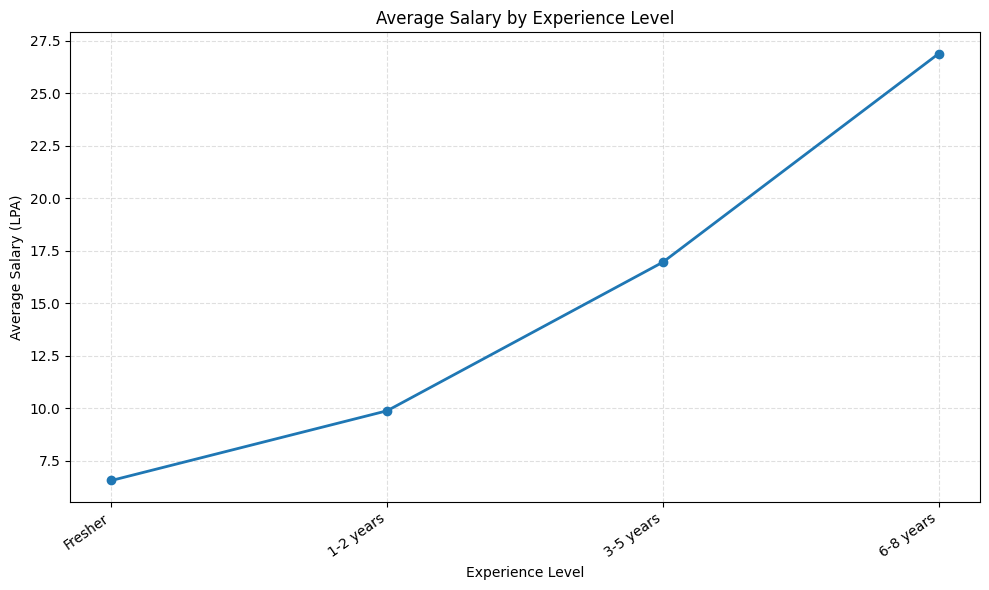


--- GRAPH MENU ---
1. Top Skills
2. Job Role Distribution
3. Top Locations
4. Salary by Experience
5. Fresher-Friendly Jobs
0. Return to Main Menu

===== JOB MARKET SKILL ANALYSIS SYSTEM =====
1. Dataset Overview
2. Preprocessing Report
3. Top Skills
4. Job Role Analysis
5. Location Analysis
6. Salary by Experience
7. Fresher-Friendly Jobs
8. Skills for a Selected Role
9. View Graphs
0. Exit
Enter your choice: 0
Thank you for using the Job Market Skill Analysis System!


In [ ]:

# MAIN CODE

import pandas as pd
import matplotlib.pyplot as plt

DATASET_PATH = "job_market_skill_analysis_synthetic_2500.csv"


# MODULE 1: LOAD DATASET
def load_dataset():
    try:
        data = pd.read_csv(DATASET_PATH)
        print("Dataset loaded successfully!")
        print("Total records:", len(data))
        return data
    except FileNotFoundError:
        print("Dataset file not found. Please upload the CSV file.")
        return None


# MODULE 2: PREPROCESS DATA
def preprocess_data(data):
    data = data.copy()
    original_records = len(data)

    # Remove duplicate job IDs
    before_duplicates = len(data)
    data = data.drop_duplicates(subset=["Job_ID"])
    duplicates_removed = before_duplicates - len(data)

    # Clean text columns
    text_columns = [
        "Job_Title", "Company", "Location", "Experience",
        "Skills", "Education", "Employment_Type",
        "Work_Mode", "Fresher_Friendly"
    ]

    for column in text_columns:
        data[column] = (
            data[column].fillna("").astype(str).str.strip()
        )

    # Convert posting date
    data["Posted_Date"] = pd.to_datetime(
        data["Posted_Date"], errors="coerce"
    )

    # Convert salary columns to numeric values
    salary_columns = [
        "Salary_Min_LPA",
        "Salary_Max_LPA",
        "Salary_Midpoint_LPA"
    ]

    for column in salary_columns:
        data[column] = pd.to_numeric(
            data[column], errors="coerce"
        )

    # Identify invalid salary ranges
    invalid_salary = (
        (data["Salary_Min_LPA"] < 0) |
        (data["Salary_Max_LPA"] < 0) |
        (
            data["Salary_Min_LPA"].notna() &
            data["Salary_Max_LPA"].notna() &
            (data["Salary_Min_LPA"] > data["Salary_Max_LPA"])
        )
    )

    invalid_salary_count = int(invalid_salary.sum())

    data.loc[invalid_salary, salary_columns] = float("nan")

    # Calculate midpoint using minimum and maximum salary
    valid_salary = (
        data["Salary_Min_LPA"].notna() &
        data["Salary_Max_LPA"].notna()
    )

    data.loc[valid_salary, "Salary_Midpoint_LPA"] = (
        data.loc[valid_salary, "Salary_Min_LPA"] +
        data.loc[valid_salary, "Salary_Max_LPA"]
    ) / 2

    report = {
        "Original records": original_records,
        "Duplicate records removed": duplicates_removed,
        "Invalid salary records": invalid_salary_count,
        "Remaining records": len(data)
    }

    return data, report


# MODULE 3: DATASET OVERVIEW
def dataset_overview(data):
    print("\n--- DATASET OVERVIEW ---")
    print("Rows:", data.shape[0])
    print("Columns:", data.shape[1])

    print("\nColumn names:")
    print(data.columns.tolist())

    print("\nFirst five records:")
    display(data.head())

    print("\nMissing values in each column:")
    print(data.isnull().sum())


# MODULE 4: PREPROCESSING REPORT
def preprocessing_report(data, report):
    print("\n--- PREPROCESSING REPORT ---")

    for key, value in report.items():
        print(f"{key}: {value}")

    print("\nMissing values after preprocessing:")
    print(data.isnull().sum())


# MODULE 5: SKILL ANALYSIS
def get_skill_counts(data):
    skills = (
        data["Skills"]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    skills = skills[skills != ""]
    return skills.value_counts()


def top_skills(data):
    print("\n--- TOP 10 SKILLS ---")
    print(get_skill_counts(data).head(10))


# MODULE 6: JOB ROLE ANALYSIS
def job_role_analysis(data):
    roles = data["Job_Title"].replace("", pd.NA).dropna()

    print("\n--- JOB ROLE ANALYSIS ---")
    print(roles.value_counts())


# MODULE 7: LOCATION ANALYSIS
def location_analysis(data):
    locations = data["Location"].replace("", pd.NA).dropna()

    print("\n--- TOP 10 LOCATIONS ---")
    print(locations.value_counts().head(10))


# MODULE 8: SALARY ANALYSIS
def salary_by_experience(data):
    valid_data = data.dropna(
        subset=["Experience", "Salary_Midpoint_LPA"]
    )

    result = valid_data.groupby("Experience").agg(
        Average_Salary_LPA=("Salary_Midpoint_LPA", "mean"),
        Job_Listings=("Job_ID", "count")
    ).round(2)

    print("\n--- SALARY BY EXPERIENCE ---")
    display(result)


# MODULE 9: FRESHER OPPORTUNITY ANALYSIS
def fresher_analysis(data):
    fresher_data = data[
        data["Fresher_Friendly"].str.casefold().isin(
            ["yes", "true", "1"]
        )
    ]

    result = fresher_data.groupby("Job_Title").agg(
        Job_Listings=("Job_ID", "count"),
        Average_Salary_LPA=("Salary_Midpoint_LPA", "mean")
    ).round(2)

    result = result.sort_values(
        "Job_Listings", ascending=False
    )

    print("\n--- FRESHER-FRIENDLY JOBS ---")
    display(result)


# MODULE 10: SKILLS FOR A SELECTED ROLE
def skills_for_role(data):
    role = input("Enter a job role: ").strip()

    matching_data = data[
        data["Job_Title"].str.casefold() == role.casefold()
    ]

    if matching_data.empty:
        print("Role not found.")
        print("Available roles:")
        print(sorted(data["Job_Title"].dropna().unique()))
        return

    print("\nMatching job listings:", len(matching_data))
    print("\nTop skills for", role)
    print(get_skill_counts(matching_data).head(10))


# MODULE 11: GRAPH 1 - TOP SKILLS
def graph_top_skills(data):
    counts = get_skill_counts(data).head(10).sort_values()

    if counts.empty:
        print("No skill data available.")
        return

    counts.plot(kind="barh", title="Top 10 In-Demand Skills")
    plt.xlabel("Number of Mentions")
    plt.ylabel("Skills")
    plt.tight_layout()
    plt.show()


# MODULE 12: GRAPH 2 - JOB ROLE DISTRIBUTION
# CHANGED TO A DONUT CHART
def graph_job_roles(data):
    roles = (
        data["Job_Title"]
        .replace("", pd.NA)
        .dropna()
        .value_counts()
    )

    if roles.empty:
        print("No job role data available.")
        return

    # Show the top five job roles and combine the rest
    top_roles = roles.head(5).copy()
    other_count = roles.iloc[5:].sum()

    if other_count > 0:
        top_roles["Others"] = other_count

    # Create the donut chart
    fig, ax = plt.subplots(figsize=(9, 7))

    wedges, texts, autotexts = ax.pie(
        top_roles.values,
        labels=None,
        autopct="%1.1f%%",
        startangle=90,
        pctdistance=0.78,
        wedgeprops={
            "width": 0.40,
            "edgecolor": "white",
            "linewidth": 2
        },
        textprops={"fontsize": 9}
    )

    # Display total listings in the centre
    ax.text(
        0, 0,
        f"{top_roles.sum():,}\nListings",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

    # Display job role names in a legend
    ax.legend(
        wedges,
        top_roles.index,
        title="Job Roles",
        loc="lower center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=2,
        fontsize=9
    )

    ax.set_title("Job Role Distribution", fontsize=14)
    ax.set_aspect("equal")

    plt.tight_layout()
    plt.show()


# MODULE 13: GRAPH 3 - LOCATION DISTRIBUTION
def graph_locations(data):
    counts = (
        data["Location"]
        .replace("", pd.NA)
        .dropna()
        .value_counts()
        .head(10)
        .sort_values()
    )

    if counts.empty:
        print("No location data available.")
        return

    counts.plot(kind="bar", title="Top 10 Job Locations")
    plt.xlabel("Location")
    plt.ylabel("Number of Job Listings")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# MODULE 14: GRAPH 4 - SALARY BY EXPERIENCE
# Updated to match the graph shown in the project presentation
def graph_salary_experience(data):
    salary_data = data.dropna(
        subset=["Experience", "Salary_Midpoint_LPA"]
    )

    if salary_data.empty:
        print("No salary data available for the graph.")
        return

    averages = salary_data.groupby("Experience")[
        "Salary_Midpoint_LPA"
    ].mean()

    # Arrange experience levels in the same order as the PPT graph
    experience_order = [
        "Fresher", "1-2 years", "3-5 years", "6-8 years"
    ]

    ordered_labels = [
        level for level in experience_order if level in averages.index
    ]

    # Include any other experience labels present in the dataset
    ordered_labels += [
        level for level in averages.index if level not in ordered_labels
    ]

    averages = averages.reindex(ordered_labels)

    plt.figure(figsize=(10, 6))
    plt.plot(
        averages.index,
        averages.values,
        marker="o",
        linewidth=2
    )
    plt.title("Average Salary by Experience Level")
    plt.xlabel("Experience Level")
    plt.ylabel("Average Salary (LPA)")
    plt.xticks(rotation=35, ha="right")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


# MODULE 15: GRAPH 5 - FRESHER-FRIENDLY JOBS
def graph_fresher_jobs(data):
    labels = data["Fresher_Friendly"].str.casefold().isin(
        ["yes", "true", "1"]
    ).map({
        True: "Fresher-Friendly",
        False: "Not Fresher-Friendly"
    })

    counts = labels.value_counts()

    if counts.empty:
        print("No fresher-friendly data available.")
        return

    counts.plot(
        kind="pie",
        autopct="%1.1f%%",
        title="Fresher-Friendly vs Other Listings",
        ylabel=""
    )

    plt.tight_layout()
    plt.show()


# MODULE 16: GRAPH MENU
def show_graphs(data):
    while True:
        print("\n--- GRAPH MENU ---")
        print("1. Top Skills")
        print("2. Job Role Distribution")
        print("3. Top Locations")
        print("4. Salary by Experience")
        print("5. Fresher-Friendly Jobs")
        print("0. Return to Main Menu")

        choice = input("Enter your choice: ").strip()

        if choice == "1":
            graph_top_skills(data)

        elif choice == "2":
            graph_job_roles(data)

        elif choice == "3":
            graph_locations(data)

        elif choice == "4":
            graph_salary_experience(data)

        elif choice == "5":
            graph_fresher_jobs(data)

        elif choice == "0":
            break

        else:
            print("Invalid choice. Please try again.")


# MODULE 17: MAIN MENU
def main():
    data = load_dataset()

    if data is None:
        return

    data, report = preprocess_data(data)

    while True:
        print("\n===== JOB MARKET SKILL ANALYSIS SYSTEM =====")
        print("1. Dataset Overview")
        print("2. Preprocessing Report")
        print("3. Top Skills")
        print("4. Job Role Analysis")
        print("5. Location Analysis")
        print("6. Salary by Experience")
        print("7. Fresher-Friendly Jobs")
        print("8. Skills for a Selected Role")
        print("9. View Graphs")
        print("0. Exit")

        choice = input("Enter your choice: ").strip()

        if choice == "1":
            dataset_overview(data)

        elif choice == "2":
            preprocessing_report(data, report)

        elif choice == "3":
            top_skills(data)

        elif choice == "4":
            job_role_analysis(data)

        elif choice == "5":
            location_analysis(data)

        elif choice == "6":
            salary_by_experience(data)

        elif choice == "7":
            fresher_analysis(data)

        elif choice == "8":
            skills_for_role(data)

        elif choice == "9":
            show_graphs(data)

        elif choice == "0":
            print("Thank you for using the Job Market Skill Analysis System!")
            break

        else:
            print("Invalid choice. Please enter a valid option.")


# RUN THE PROJECT
main()


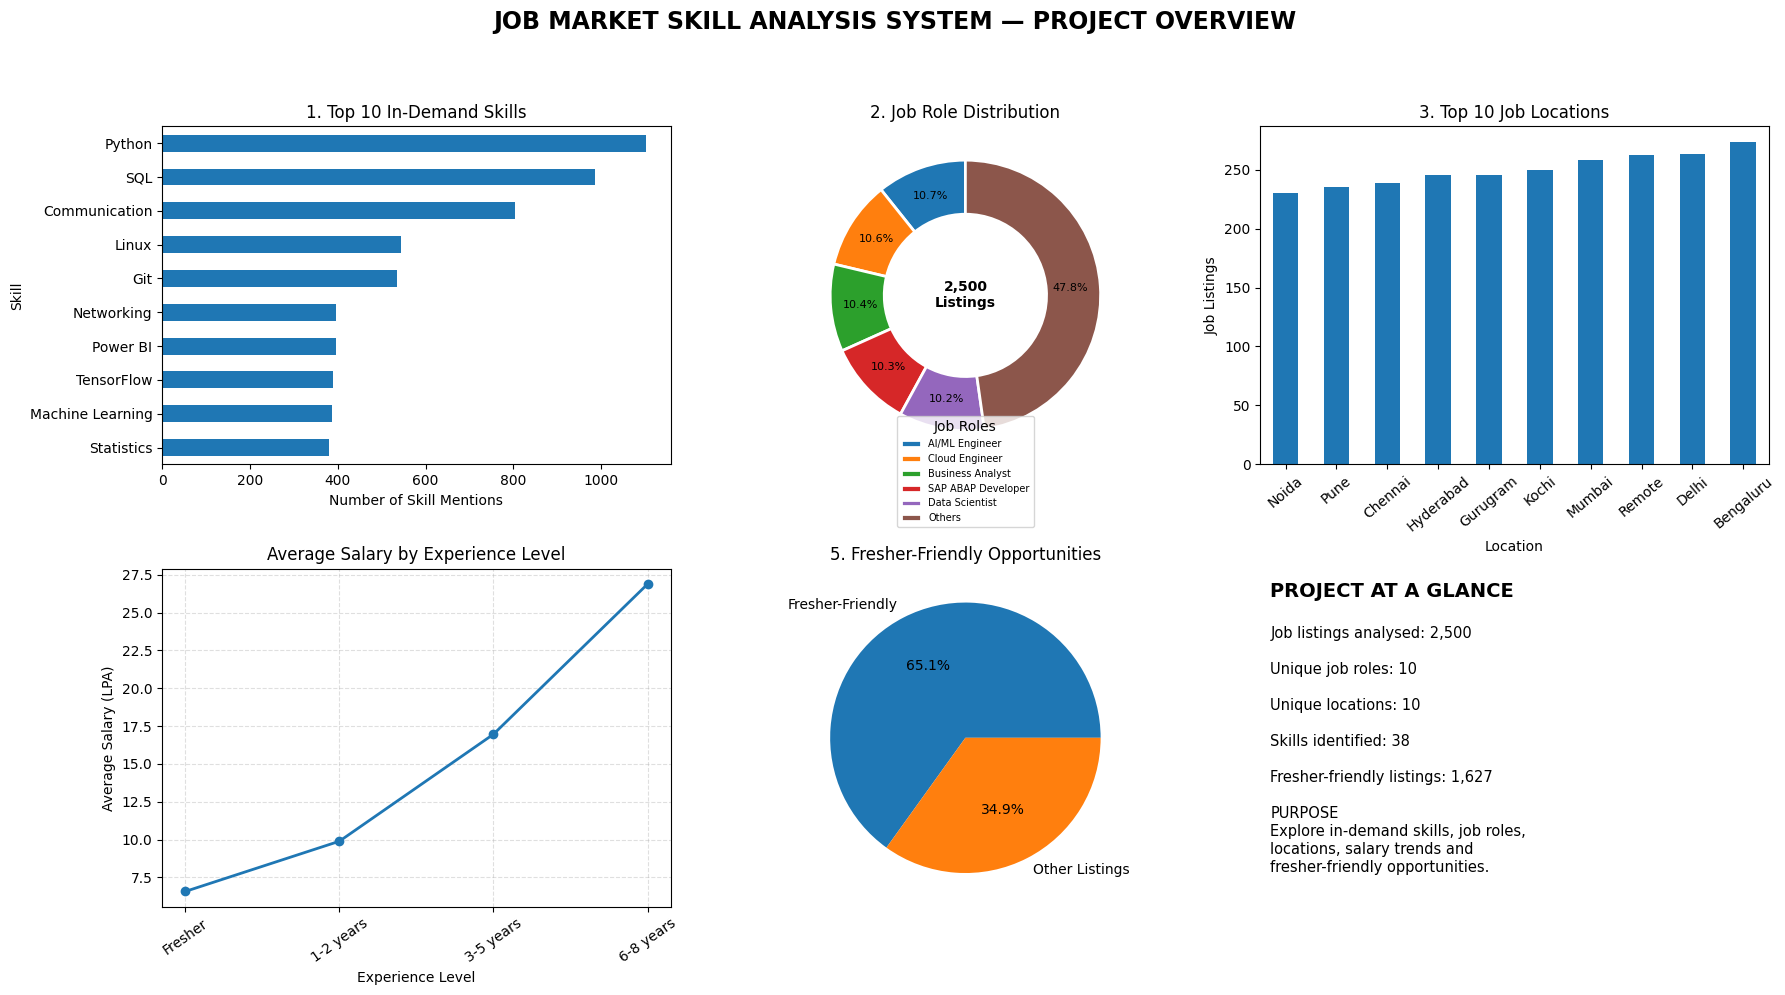

In [ ]:

# DASHBOARD

import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# JOB MARKET SKILL ANALYSIS SYSTEM
# SINGLE DASHBOARD / PROJECT OVERVIEW
# ==========================================

# 1. Load dataset
file_path = "/content/job_market_skill_analysis_synthetic_2500.csv"
df = pd.read_csv(file_path)

# 2. Prepare required columns
df = df.drop_duplicates(subset=["Job_ID"]).copy()

for col in ["Skills", "Job_Title", "Location",
            "Experience", "Fresher_Friendly"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

for col in ["Salary_Min_LPA", "Salary_Max_LPA"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Calculate salary midpoint
valid_salary = (
    (df["Salary_Min_LPA"] >= 0) &
    (df["Salary_Max_LPA"] >= df["Salary_Min_LPA"])
)

df["Salary_Midpoint_LPA"] = float("nan")

df.loc[valid_salary, "Salary_Midpoint_LPA"] = (
    df.loc[valid_salary, "Salary_Min_LPA"] +
    df.loc[valid_salary, "Salary_Max_LPA"]
) / 2

# ------------------------------------------
# ANALYSIS 1: TOP SKILLS
# ------------------------------------------
skill_counts = (
    df["Skills"].str.split(",").explode().str.strip()
)

skill_counts = skill_counts[
    skill_counts != ""
].value_counts()

top_skills = skill_counts.head(10).sort_values()

# ------------------------------------------
# ANALYSIS 2: JOB ROLE DISTRIBUTION
# ------------------------------------------
role_counts = (
    df["Job_Title"].replace("", pd.NA)
    .dropna()
    .value_counts()
)

top_roles = role_counts.head(5).copy()
other_roles = role_counts.iloc[5:].sum()

if other_roles > 0:
    top_roles["Others"] = other_roles

# ------------------------------------------
# ANALYSIS 3: TOP LOCATIONS
# ------------------------------------------
location_counts = (
    df["Location"].replace("", pd.NA)
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

# ------------------------------------------
# ANALYSIS 4: SALARY BY EXPERIENCE
# ------------------------------------------
salary_data = df.dropna(
    subset=["Experience", "Salary_Midpoint_LPA"]
)

salary_by_experience = salary_data.groupby(
    "Experience"
)["Salary_Midpoint_LPA"].mean()

# Experience order from the PPT
experience_order = [
    "Fresher", "0-1 years", "0-2 years", "1-2 years",
    "1-3 years", "2-3 years", "3-5 years", "5-7 years",
    "5-10 years", "7-10 years", "10+ years"
]

ordered_labels = [
    level for level in experience_order
    if level in salary_by_experience.index
]

# Include any other experience labels in the dataset
ordered_labels += [
    level for level in salary_by_experience.index
    if level not in ordered_labels
]

salary_by_experience = salary_by_experience.reindex(
    ordered_labels
)

# ------------------------------------------
# ANALYSIS 5: FRESHER-FRIENDLY OPPORTUNITIES
# ------------------------------------------
is_fresher_friendly = df["Fresher_Friendly"].str.casefold().isin(
    ["yes", "true", "1"]
)

fresher_counts = pd.Series({
    "Fresher-Friendly": int(is_fresher_friendly.sum()),
    "Other Listings": int((~is_fresher_friendly).sum())
})

# ------------------------------------------
# CREATE ONE DASHBOARD WITH FIVE GRAPHS
# ------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

fig.suptitle(
    "JOB MARKET SKILL ANALYSIS SYSTEM — PROJECT OVERVIEW",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

# GRAPH 1: TOP SKILLS
if not top_skills.empty:
    top_skills.plot(kind="barh", ax=axes[0, 0])

axes[0, 0].set_title("1. Top 10 In-Demand Skills")
axes[0, 0].set_xlabel("Number of Skill Mentions")
axes[0, 0].set_ylabel("Skill")

# GRAPH 2: JOB ROLE DISTRIBUTION — DONUT CHART
ax = axes[0, 1]

if not top_roles.empty:
    wedges, texts, autotexts = ax.pie(
        top_roles.values,
        labels=None,
        autopct="%1.1f%%",
        startangle=90,
        pctdistance=0.78,
        wedgeprops={
            "width": 0.40,
            "edgecolor": "white",
            "linewidth": 2
        },
        textprops={"fontsize": 8}
    )

    ax.text(
        0, 0,
        f"{top_roles.sum():,}\nListings",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

    ax.legend(
        wedges,
        top_roles.index,
        title="Job Roles",
        loc="lower center",
        bbox_to_anchor=(0.5, -0.20),
        fontsize=7
    )

ax.set_title("2. Job Role Distribution")
ax.set_aspect("equal")

# GRAPH 3: TOP LOCATIONS
if not location_counts.empty:
    location_counts.plot(kind="bar", ax=axes[0, 2])

axes[0, 2].set_title("3. Top 10 Job Locations")
axes[0, 2].set_xlabel("Location")
axes[0, 2].set_ylabel("Job Listings")
axes[0, 2].tick_params(axis="x", rotation=40)

# ------------------------------------------
# GRAPH 4: SALARY BY EXPERIENCE
# UPDATED TO MATCH THE PPT
# ------------------------------------------
ax = axes[1, 0]

if not salary_by_experience.empty:
    ax.plot(
        salary_by_experience.index,
        salary_by_experience.values,
        marker="o",
        linewidth=2
    )

    ax.set_title("Average Salary by Experience Level")
    ax.set_xlabel("Experience Level")
    ax.set_ylabel("Average Salary (LPA)")
    ax.tick_params(axis="x", rotation=35)

    # Grid lines as shown in the PPT
    ax.grid(True, linestyle="--", alpha=0.4)

# ------------------------------------------
# GRAPH 5: FRESHER-FRIENDLY OPPORTUNITIES
# ------------------------------------------
fresher_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1, 1],
    ylabel=""
)

axes[1, 1].set_title("5. Fresher-Friendly Opportunities")

# ------------------------------------------
# PROJECT OVERVIEW PANEL
# ------------------------------------------
axes[1, 2].axis("off")

axes[1, 2].text(
    0.02, 0.96,
    "PROJECT AT A GLANCE",
    fontsize=14,
    fontweight="bold",
    va="top"
)

overview = (
    f"Job listings analysed: {len(df):,}\n\n"
    f"Unique job roles: "
    f"{df['Job_Title'].replace('', pd.NA).nunique()}\n\n"
    f"Unique locations: "
    f"{df['Location'].replace('', pd.NA).nunique()}\n\n"
    f"Skills identified: {len(skill_counts)}\n\n"
    f"Fresher-friendly listings: "
    f"{is_fresher_friendly.sum():,}\n\n"
    "PURPOSE\n"
    "Explore in-demand skills, job roles,\n"
    "locations, salary trends and\n"
    "fresher-friendly opportunities."
)

axes[1, 2].text(
    0.02, 0.83,
    overview,
    fontsize=10.5,
    va="top",
    linespacing=1.25
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
